In [75]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

# always make a copy
df_work = df.copy()

In [77]:
df_head = df.head()
df.shape  # (rows, cols)
df_info = df.info()  # dtypes + non-null counts
df_dtype = df.dtypes  # data type per column
df.columns  # list of column names
de_descr = df.describe()  # stats for numeric cols
df.describe(include="all")  # all cols
df_transposed = round(df.describe().T, 2)  # transposed
missing = df.isna().sum()
missing[missing > 0]
missing

<class 'pandas.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               str    
 2   title              str    
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           str    
dtypes: bool(1), float64(2), int64(3), str(3)
memory usage: 151.5 MB


uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

# Frequency Tables:

## Generate a frequency table for the product category.
Which are the top 5 most listed product categories?
Visualizations:

## Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories.
For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

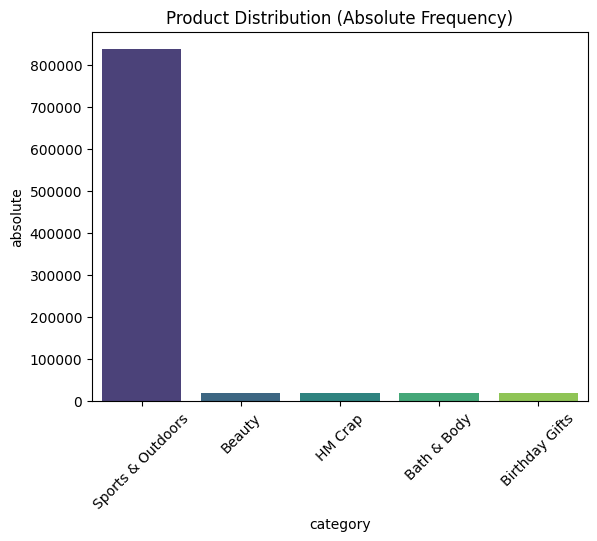

In [ ]:
# Absolute frequency (counts)
from re import A


freq_df = df["category"].value_counts().reset_index()

# Relative frequency (proportions 0–1)
prop = df.category.value_counts(normalize=True).round(2)

# Combine into one table
df2 = pd.concat([freq_df, prop], axis=1)

df2.columns = ["category", "absolute", "relative"]
# Single variable — frequency table
pd.crosstab(index=df.category, columns="freq").sort_values(ascending=False, by="freq")

# Sorty by "absolute" top 5
top_5_df = df2.sort_values(by="absolute", ascending=False).head(5)
top_5_df["category"] = top_5_df["category"].replace(
    "Handmade Clothing, Shoes & Accessories", "HM Crap"
)
# 3. Now sns.barplot will work because 'absolute' exists in freq_df
sns.barplot(x="category", y="absolute", data=top_5_df, palette="viridis", hue="category")
plt.xticks(rotation=45)
plt.title("Product Distribution (Absolute Frequency)")
plt.show()


# Part 2: Delving into Product Pricing
Business Question: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

## Measures of Centrality:
    Calculate the mean, median, and mode for the price of products.
    What's the average price point of products listed? How does this compare with the most common price point (mode)?

## Measures of Dispersion:
    Determine the variance, standard deviation, range, and interquartile range for product price.
    How varied are the product prices? Are there any indicators of a significant spread in prices?

## Visualizations:
    Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. If its hard to read these diagrams, think why this is, and explain how it could be solved..
    Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.

In [ ]:
# mean
mean_price = round(df["price"].mean(), 2)
# med
median_price = df["price"].median()
# mode
mode_price = df["price"].mode()[0]
print(
    f"The mean price is: {mean_price}\nThe median price is: {median_price}\nThe mode price is: {mode_price}"
)

# The mean is much bigger than median, that results in right-skewed. The average price is 89.24$ but the most frequent price is 9.99$

The mean price is: 89.24
The median price is: 19.09
The mode price is: 9.99


In [ ]:
# Variance
var_price = round(df["price"].var(), 2)
# SD
sd_price = round(df["price"].std(), 2)
# Range
range_price = df["price"].max() - df["price"].min()
# interquartile range
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR_price = Q3 - Q1
print(
    f"The Variance is: {var_price}\nThe SD is: {sd_price}\nThe Range is: {range_price}\nThe IQR is: {IQR_price}"
)

# The variance is very high so it confirms the "spread" of my data, is very volatile. Standard deviation vs IQR, standard deviation is veru high so there are oulier which are pulling the SD up.
# IQR is ignoring the outliers so it gives us a true story of the data.
# How big is the outliers we can see in range result.

The Variance is: 119445.49
The SD is: 345.61
The Range is: 100000.0
The IQR is: 36.0


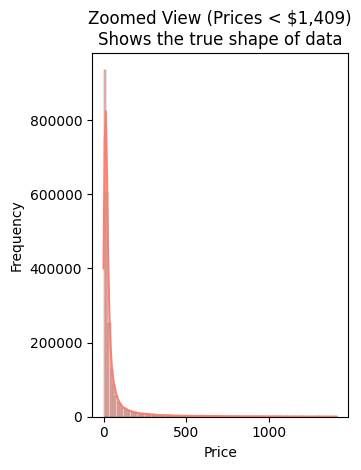

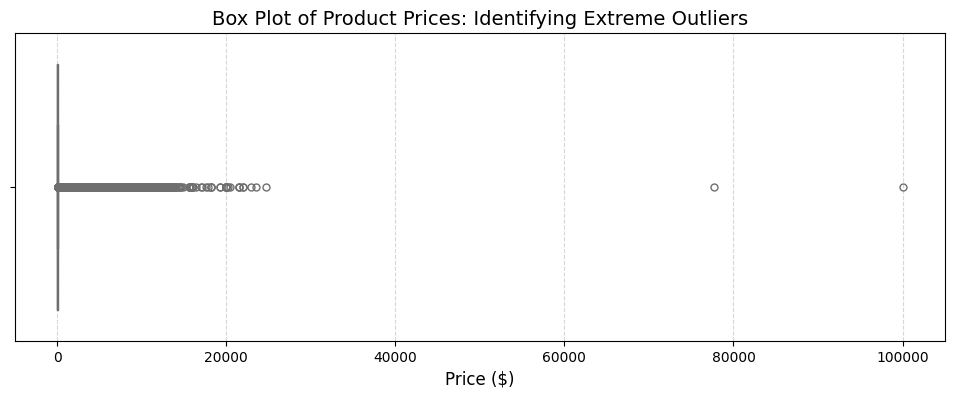

In [ ]:
plt.subplot(1, 2, 2)
upper_limit = df["price"].quantile(0.99)
sns.histplot(df[df["price"] <= upper_limit]["price"], bins=100, kde=True, color="salmon")
plt.title(f"Zoomed View (Prices < ${upper_limit:,.0f})\nShows the true shape of data")
plt.xlabel("Price")
plt.ylabel("Frequency")

plt.tight_layout()
plt.savefig("price_distribution.png")

# Create the box plot
plt.figure(figsize=(12, 4))
sns.boxplot(x=df["price"], color="skyblue", fliersize=5)

# Add titles and labels
plt.title("Box Plot of Product Prices: Identifying Extreme Outliers", fontsize=14)
plt.xlabel("Price ($)", fontsize=12)
plt.grid(axis="x", linestyle="--", alpha=0.5)

plt.savefig("price_boxplot.png")

# Part 3: Unpacking Product Ratings
Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

## Measures of Centrality:

Calculate the mean, median, and mode for the rating of products.
How do customers generally rate products? Is there a common trend?

## Measures of Dispersion:

Determine the variance, standard deviation, and interquartile range for product rating.
Are the ratings consistent, or is there a wide variation in customer feedback?

## Shape of the Distribution:

Calculate the skewness and kurtosis for the rating column.
Are the ratings normally distributed, or do they lean towards higher or lower values?

## Visualizations:

Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

C:\Users\felic\AppData\Local\Temp\ipykernel_11864\199982252.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='stars', data=df, palette='viridis')


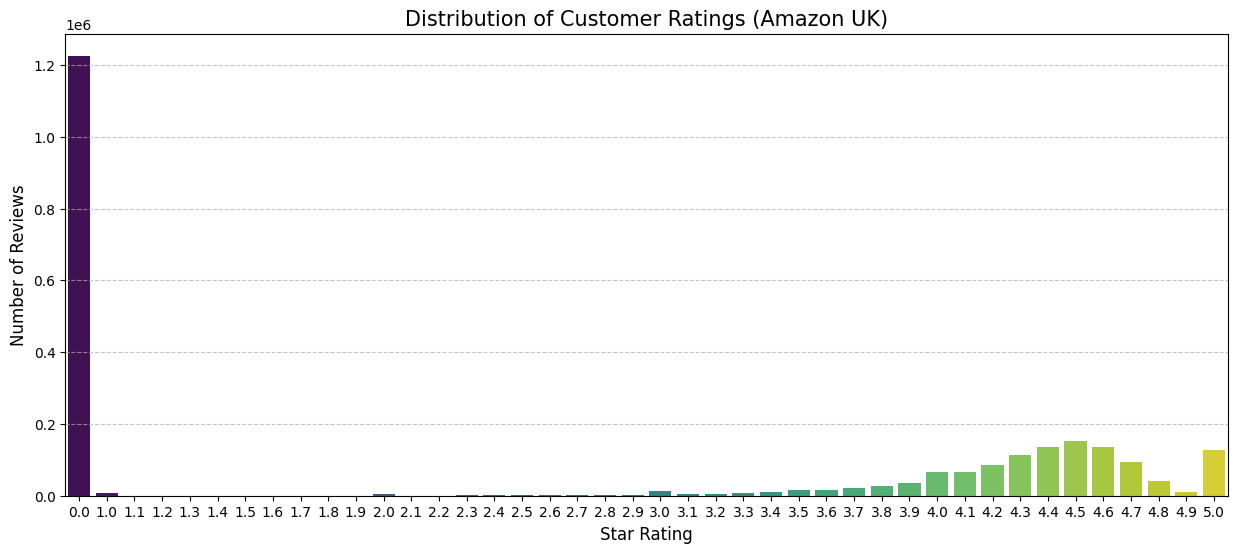

In [ ]:
# 1. Visualizing Rating Patterns (Histogram)
# Create a count plot for discrete ratings (1-5 stars)
plt.figure(figsize=(15, 6))
sns.countplot(x="stars", data=df, palette="viridis")

plt.title("Distribution of Customer Ratings (Amazon UK)", fontsize=15)
plt.xlabel("Star Rating", fontsize=12)
plt.ylabel("Number of Reviews", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

# The reviews are Top-Heavy, most of the reviews are 0 or missing, if the reviews scale starts from 1 to 5 then most products don;t have a review.

In [ ]:
# Calculate the mean, median, and mode for the rating of products.
# mean
mean_stars = round(df["stars"].mean(), 2)
# med
median_stars = df["stars"].median()
# mode
mode_stars = df["stars"].mode()[0]
print(
    f"The mean stars is: {mean_stars}\nThe median stars is: {median_stars}\nThe mode stars is: {mode_stars}"
)

# The average star is 2.15 where the median and mode are 0. The trend is that the customers do not review the products or it tend to no leave a rview

The mean stars is: 2.15
The median stars is: 0.0
The mode stars is: 0.0


In [ ]:
# Determine the variance, standard deviation, and interquartile range for product rating.
# Are the ratings consistent, or is there a wide variation in customer feedback?

# Variance
var_star = round(df["stars"].var(), 2)
# SD
sd_star = round(df["stars"].std(), 2)
# Range
range_star = df["stars"].max() - df["stars"].min()
# interquartile range
Q1 = df["stars"].quantile(0.25)
Q3 = df["stars"].quantile(0.75)
IQR_star = Q3 - Q1
print(
    f"The Variance is: {var_star}\nThe SD is: {sd_star}\nThe Range is: {range_star}\nThe IQR is: {IQR_star}"
)

# IQR is 4.4 this means the "middle 50%" of  customers are not agreeing at all. A huge concentration of people
# at the very bottom (0 star) and the very top (5 stars). Data is likely bimodal, looking like a "U" shape rather than a bell curve.
# SD of 2.19 on a 5 point scase is extrimly high In a typical "healthy" product, you'd expect an SD below 1.0 (meaning most people
# agree the product is a 4 or 5). An SD of 2.19 confirms that "average" rating is essentially meaningless because the actual
# ratings are scattered to the extreme edges.
# Range confirms all what been said.

The Variance is: 4.82
The SD is: 2.19
The Range is: 5.0
The IQR is: 4.4


In [ ]:
# Calculate the skewness and kurtosis for the rating column.
# Are the ratings normally distributed, or do they lean towards higher or lower values?

df["stars"].skew()
skew_stars = round(float(df["stars"].skew()), 2)
print(f"The skew is: {skew_stars}")

# skew < 0 means long left tail, bulk on right mean < median.

The skew is: 0.08
